In [2]:
%pip install shap

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ----------------------------- ---------- 2.1/2.8 MB 10.7 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 9.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   -- ------------------------------------- 2.4/41.9 MB 10.9 MB/s eta 0:00:04
   ---- ----------------------------------- 4.5/41.9 MB 11.0 MB/s eta 0:00:04
   ------ --------------------------------- 6.8/41.9 MB 10.8 MB/s eta 0:00:04
   --------- ------------------------------ 9.4/41.9 MB 10.8 MB/s eta 0:00:03
   ----------- ---------------------------- 11.5/41.9 MB 10.8 MB/s eta 0:00:03
   ------------- -------------------------- 14.4/41.9 MB 11.1 MB/s eta 0:00:03
   ---------------- ----------------------- 17.0/41.9 MB 11.3 MB/s eta 0:00:03
   ------------------- -------------------- 19.9/41.9 MB 11.6 MB/s eta 0:00:02
   ---------------------- ----------------- 23.1/41.9 MB 11.9 MB/s eta 0:00:02
 

# 12 - Stage 2 SHAP Explanations

This notebook explains the saved all-numeric LightGBM model using SHAP. It reports global feature importance and worked conversation-level explanations using numeric Stage 1 and behavioral features.

Only a bounded, stratified sample of conversations is used for SHAP because the full PAN-12 test matrix is large.

In [7]:
from pathlib import Path
import json
import joblib

import numpy as np
import pandas as pd

try:
    import shap
except ImportError as exc:
    raise ImportError("Install SHAP with `pip install shap` before running this notebook.") from exc

RANDOM_SEED = 42
WORKSPACE = Path.cwd()
PROCESSED_DIR = WORKSPACE / "data" / "processed"
REPORT_DIR = WORKSPACE / "reports"
MODEL_DIR = WORKSPACE / "models"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "stage2_lightgbm_all_numeric.joblib"
features_path = PROCESSED_DIR / "pan12_conversation_features.csv"
if not model_path.exists():
    raise FileNotFoundError("Run 11_stage2_lightgbm.ipynb first.")
if not features_path.exists():
    raise FileNotFoundError("Run 09_pan12_stage2_features.ipynb first.")

conversations = pd.read_csv(features_path)
stage_columns = [
    column for column in [
        "fraction_predicted_200", "fraction_predicted_600", "fraction_predicted_900",
        "stage_600_threshold_onset", "stage_900_threshold_onset",
        "mean_stage_600_probability", "mean_stage_900_probability",
        "max_stage_600_probability", "max_stage_900_probability",
    ] if column in conversations.columns
]
behavioral_columns = [
    column for column in conversations.columns
    if column not in {"split", "conversation_id", "conversation_text", "label", *stage_columns}
]
feature_columns = stage_columns + behavioral_columns
model = joblib.load(model_path)
print(f"Explaining {len(feature_columns)} numeric features")

Explaining 17 numeric features


## Explain a stratified test sample

The sample is capped at 2,000 conversations, with positive and negative rows represented as evenly as class availability permits.

In [8]:
np.random.seed(RANDOM_SEED)
test_frame = conversations.loc[conversations["split"] == "test"].copy()

sample_size = min(2000, len(test_frame))
target_per_class = sample_size // 2
samples = []
for label in [0, 1]:
    class_frame = test_frame.loc[test_frame["label"] == label]
    count = min(target_per_class, len(class_frame))
    samples.append(class_frame.sample(n=count, random_state=RANDOM_SEED))

remaining = sample_size - sum(len(sample) for sample in samples)
if remaining:
    used_indices = pd.concat(samples).index
    leftover = test_frame.drop(index=used_indices)
    if len(leftover) >= remaining:
        samples.append(leftover.sample(n=remaining, random_state=RANDOM_SEED))

explanation_frame = pd.concat(samples).sample(frac=1, random_state=RANDOM_SEED)
imputed_values = model.named_steps["impute"].transform(explanation_frame[feature_columns])
lgbm = model.named_steps["classifier"]

explainer = shap.TreeExplainer(lgbm)
raw_values = explainer.shap_values(imputed_values)
if isinstance(raw_values, list):
    shap_values = raw_values[1] if len(raw_values) > 1 else raw_values[0]
else:
    shap_values = np.asarray(raw_values)
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, -1]

print("SHAP matrix:", shap_values.shape)
print(explanation_frame["label"].value_counts().to_string())

SHAP matrix: (2000, 17)
label
1    1000
0    1000


c:\Users\Kruti\anaconda3\Lib\site-packages\shap\explainers\_tree.py:587: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


## Global feature importance

Mean absolute SHAP value is shown because a feature can raise risk in some conversations and lower it in others.

,feature,mean_abs_shap
9,message_count,1.011652
16,duration_minutes,1.006064
10,mean_message_length,0.952820
12,author_count,0.802624
8,max_stage_900_probability,0.517991
14,question_share,0.321600
6,mean_stage_900_probability,0.305016
13,dominant_author_share,0.299195
7,max_stage_600_probability,0.172543
11,std_message_length,0.167683


C:\Users\Kruti\AppData\Local\Temp\ipykernel_4816\2512640801.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, imputed_values, feature_names=feature_columns, show=False)


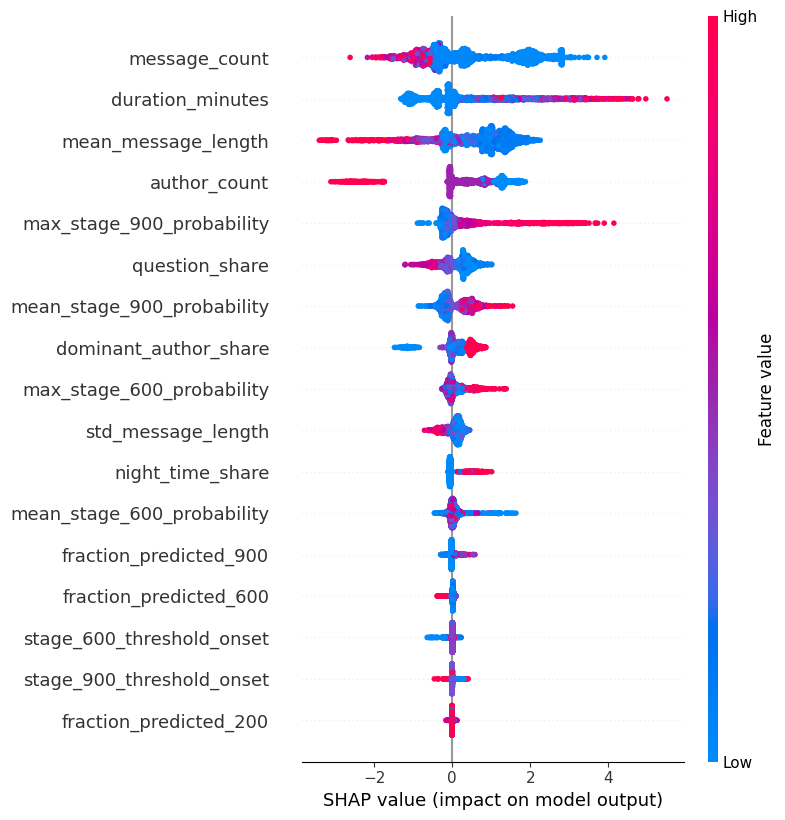

In [9]:
importance = pd.DataFrame({
    "feature": feature_columns,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)

display(importance.head(20))
importance.to_csv(REPORT_DIR / "stage2_shap_feature_importance.csv", index=False)

shap.summary_plot(shap_values, imputed_values, feature_names=feature_columns, show=False)


rows = []
for example_name, example in examples.items():
    row_position = explanation_frame.index.get_loc(example.name)
    contributions = pd.Series(shap_values[row_position], index=feature_columns).sort_values(key=lambda values: np.abs(values), ascending=False)
    top_contributors = {feature: float(contributions[feature]) for feature in contributions.head(10).index}
    rows.append({
        "example": example_name,
        "conversation_id": example["conversation_id"],
        "label": int(example["label"]),
        "risk_score": float(example["risk_score"]),
        "top_contributors": top_contributors,
    })

with (REPORT_DIR / "stage2_shap_worked_examples.json").open("w", encoding="utf-8") as handle:
    json.dump(rows, handle, indent=2)

for row in rows:
    print(f"{row['example']}: conversation={row['conversation_id']}, risk={row['risk_score']:.4f}")
    for feature, contribution in row["top_contributors"].items():
        direction = "raises" if contribution > 0 else "lowers"
        print(f"  - {feature}: {direction} risk (SHAP {contribution:+.4f})")


In [6]:
scores = model.predict_proba(explanation_frame[feature_columns])[:, 1]
worked = explanation_frame.assign(risk_score=scores).copy()

positives = worked.loc[worked["label"] == 1]
negatives = worked.loc[worked["label"] == 0]
examples = {}
if len(positives):
    examples["highest_risk_true_positive"] = positives.loc[positives["risk_score"].idxmax()]
if len(negatives):
    examples["highest_scoring_negative"] = negatives.loc[negatives["risk_score"].idxmax()]

rows = []
for example_name, example in examples.items():
    row_position = explanation_frame.index.get_loc(example.name)
    contributions = pd.Series(shap_values[row_position], index=feature_columns).sort_values(key=np.abs, ascending=False)
    top_contributors = {
        feature: float(contributions[feature])
        for feature in contributions.head(10).index
    }
    rows.append({
        "example": example_name,
        "conversation_id": example["conversation_id"],
        "label": int(example["label"]),
        "risk_score": float(example["risk_score"]),
        "top_contributors": top_contributors,
    })
with (REPORT_DIR / "stage2_shap_worked_examples.json").open("w", encoding="utf-8") as handle:
    json.dump(rows, handle, indent=2)
for row in rows:
    print(f"{row['example']}: conversation={row['conversation_id']}, risk={row['risk_score']:.4f}")
    for feature, contribution in row["top_contributors"].items():
        direction = "raises" if contribution > 0 else "lowers"
        print(f"  - {feature}: {direction} risk (SHAP {contribution:+.4f})")

highest_risk_true_positive: conversation=29962b2b3057b6e4cc886c51268a2348, risk=0.9980
  - duration_minutes: raises risk (SHAP +3.6444)
  - max_stage_900_probability: raises risk (SHAP +2.5862)
  - author_count: raises risk (SHAP +1.0320)
  - mean_message_length: raises risk (SHAP +1.0280)
  - message_count: lowers risk (SHAP -0.5443)
  - night_time_share: raises risk (SHAP +0.4499)
  - mean_stage_900_probability: raises risk (SHAP +0.4382)
  - max_stage_600_probability: raises risk (SHAP +0.4111)
  - question_share: raises risk (SHAP +0.3502)
  - dominant_author_share: raises risk (SHAP +0.2610)
highest_scoring_negative: conversation=0b67ef232ff990d3102685783a6183d9, risk=0.9872
  - max_stage_900_probability: raises risk (SHAP +2.4629)
  - duration_minutes: raises risk (SHAP +2.4133)
  - mean_message_length: raises risk (SHAP +1.4077)
  - message_count: lowers risk (SHAP -0.9015)
  - author_count: raises risk (SHAP +0.6955)
  - max_stage_600_probability: raises risk (SHAP +0.6716)
  -

## Limitations

* SHAP explains the model's learned associations, not causation or real-world safety guarantees.
* Feature values come from PAN-12 and can encode dataset/source artifacts.
* The worked examples are selected from the test sample and should not be described as a general audit.
* A parent-facing system should include uncertainty and preserve human review.